In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

In [17]:
import os, re

DATA_DIR = "data"

def read_pvgis_csv(path):
    with open(path, encoding="utf-8", errors="ignore") as f:
        lines = f.read().splitlines()
    meta = {}
    for line in lines[:15]:
        for key in ["Latitude", "Longitude", "Elevation"]:
            if line.startswith(key):
                meta[key] = float(re.findall(r"-?\d+\.?\d*", line.split(":", 1)[1])[0])
    start = next(i for i, l in enumerate(lines) if l.startswith("time,"))
    end = start + 1
    while end < len(lines) and lines[end][:1].isdigit():
        end += 1
    header = lines[start].split(",")
    rows = [l.split(",") for l in lines[start + 1:end]]
    d = pd.DataFrame(rows, columns=header)
    d["time"] = pd.to_datetime(d["time"], format="%Y%m%d:%H%M", utc=True)
    for c in d.columns[1:]:
        d[c] = d[c].astype(float)
    d["town"] = os.path.splitext(os.path.basename(path))[0]
    d["lat"], d["lon"], d["elevation"] = meta["Latitude"], meta["Longitude"], meta["Elevation"]
    return d

frames = []
for file in sorted(os.listdir(DATA_DIR)):
    if file.endswith(".csv"):
        d = read_pvgis_csv(os.path.join(DATA_DIR, file))
        frames.append(d)
        print(d["town"][0], "ok", len(d), "| has P:", "P" in d.columns)

raw = pd.concat(frames, ignore_index=True)
print("total rows:", len(raw))
print()
print("missing values per town:")
print(raw.isna().groupby(raw["town"]).sum())    

Anjar ok 17520 | has P: True
Batroun ok 17520 | has P: True
Beirut-RaficHaririAirport.csv ok 17520 | has P: True
Bekaa ok 17520 | has P: True
Daraya ok 17520 | has P: True
Faraya ok 17520 | has P: True
Port-Of-Beirut ok 17520 | has P: True
Port-Of-Tripoli ok 17520 | has P: True
ReneMouawad-Airport.csv ok 17520 | has P: True
baalbek ok 17520 | has P: True
bcharre ok 17520 | has P: True
beirut ok 17520 | has P: True
chehime ok 17520 | has P: True
debbieh ok 17520 | has P: True
halba ok 17520 | has P: True
jbeil ok 17520 | has P: True
mountlebanon ok 17520 | has P: True
nabatieh ok 17520 | has P: True
saida ok 17520 | has P: True
tripoli ok 17520 | has P: True
tyre ok 17520 | has P: True
zahle ok 17520 | has P: True
total rows: 385440

missing values per town:
                               time  P  G(i)  H_sun  T2m  WS10m  Int  town  \
town                                                                         
Anjar                             0  0     0      0    0      0    0     0  

In [18]:
print(raw.groupby("town")[["lat", "lon", "elevation"]].first())
print()
print("missing values:", raw.isna().sum().sum())
print()
print(raw.describe().round(2))

                                  lat     lon  elevation
town                                                    
Anjar                          33.739  35.930      876.0
Batroun                        34.255  35.659       10.0
Beirut-RaficHaririAirport.csv  33.834  35.496       27.0
Bekaa                          33.675  35.833      867.0
Daraya                         33.640  35.506      742.0
Faraya                         34.026  35.838     1635.0
Port-Of-Beirut                 33.903  35.525        1.0
Port-Of-Tripoli                34.451  35.828        1.0
ReneMouawad-Airport.csv        34.591  36.011        5.0
baalbek                        34.010  36.212     1172.0
bcharre                        34.252  36.042     1909.0
beirut                         33.896  35.478       64.0
chehime                        33.624  35.484      563.0
debbieh                        33.666  35.487      461.0
halba                          34.544  36.078      127.0
jbeil                          

In [19]:
df = raw.drop(columns=["Int"]).rename(columns={"G(i)": "G"})
df = df[df["G"] > 0].reset_index(drop=True)

df["power_frac"] = df["P"] / 1000

solar_hour = (df["time"].dt.hour + df["time"].dt.minute / 60 + df["lon"] / 15) % 24
doy = df["time"].dt.dayofyear

df["hour_sin"] = np.sin(2 * np.pi * solar_hour / 24)
df["hour_cos"] = np.cos(2 * np.pi * solar_hour / 24)
df["doy_sin"] = np.sin(2 * np.pi * doy / 365)
df["doy_cos"] = np.cos(2 * np.pi * doy / 365)

decl = np.radians(23.44) * np.sin(2 * np.pi * (284 + doy) / 365)
hour_angle = np.radians(15 * (solar_hour - 12))
lat_r = np.radians(df["lat"])
df["sun_elev"] = np.degrees(np.arcsin(
    np.sin(lat_r) * np.sin(decl) + np.cos(lat_r) * np.cos(decl) * np.cos(hour_angle)))

print("daytime rows:", len(df))
print("sun elevation, mine vs PVGIS, mean difference:",
      round((df["sun_elev"] - df["H_sun"]).abs().mean(), 2), "degrees")
df.head()

daytime rows: 190564
sun elevation, mine vs PVGIS, mean difference: 1.03 degrees


,time,P,G,H_sun,T2m,WS10m,town,lat,lon,elevation,power_frac,hour_sin,hour_cos,doy_sin,doy_cos,sun_elev
0,2022-01-01 05:09:00+00:00,0.71,7.32,4.33,4.22,1.45,Anjar,33.739,35.93,876.0,0.00071,0.919273,-0.393621,0.017213,0.999852,4.833965
1,2022-01-01 06:09:00+00:00,79.46,107.06,14.39,4.94,1.24,Anjar,33.739,35.93,876.0,0.07946,0.786073,-0.618134,0.017213,0.999852,14.840208
2,2022-01-01 07:09:00+00:00,184.23,226.52,22.95,7.43,1.17,Anjar,33.739,35.93,876.0,0.18423,0.599303,-0.800522,0.017213,0.999852,23.311820
3,2022-01-01 08:09:00+00:00,100.85,133.32,29.33,8.44,1.38,Anjar,33.739,35.93,876.0,0.10085,0.371692,-0.928356,0.017213,0.999852,29.576597
4,2022-01-01 09:09:00+00:00,231.36,283.03,32.80,9.33,1.31,Anjar,33.739,35.93,876.0,0.23136,0.118751,-0.992924,0.017213,0.999852,32.888837


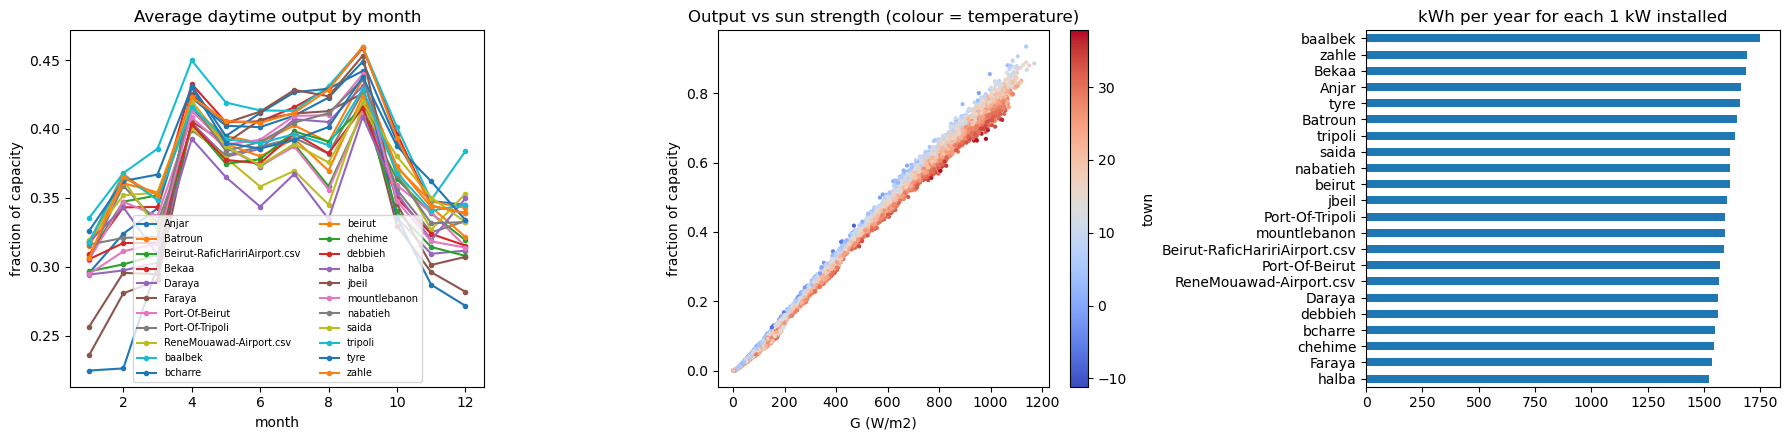

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

monthly = df.assign(month=df["time"].dt.month).groupby(["month", "town"])["power_frac"].mean().unstack()
monthly.plot(ax=ax[0], marker="o", ms=3)
ax[0].set_title("Average daytime output by month")
ax[0].set_ylabel("fraction of capacity")
ax[0].legend(fontsize=7, ncol=2)

s = df.sample(6000, random_state=0)
sc = ax[1].scatter(s["G"], s["power_frac"], c=s["T2m"], s=4, cmap="coolwarm")
ax[1].set_xlabel("G (W/m2)")
ax[1].set_ylabel("fraction of capacity")
ax[1].set_title("Output vs sun strength (colour = temperature)")
plt.colorbar(sc, ax=ax[1])

yearly = df.groupby("town")["P"].sum() / 1000 / 2
yearly.sort_values().plot.barh(ax=ax[2])
ax[2].set_title("kWh per year for each 1 kW installed")

plt.tight_layout()
plt.show()

In [21]:
FEATURES = ["G", "T2m", "WS10m", "sun_elev", "hour_sin", "hour_cos",
            "doy_sin", "doy_cos", "lat", "lon", "elevation"]
TARGET = "power_frac"
TEST_TOWNS = ["saida", "mountlebanon", "baalbek"]

is_test = df["town"].isin(TEST_TOWNS)
train = df[~is_test].reset_index(drop=True)
test = df[is_test].reset_index(drop=True)

X_train = train[FEATURES].values
y_train = train[TARGET].values
X_test = test[FEATURES].values
y_test = test[TARGET].values

print("train:", X_train.shape, "towns:", sorted(train["town"].unique()))
print("test: ", X_test.shape, "towns:", sorted(test["town"].unique()))

train: (164581, 11) towns: ['Anjar', 'Batroun', 'Beirut-RaficHaririAirport.csv', 'Bekaa', 'Daraya', 'Faraya', 'Port-Of-Beirut', 'Port-Of-Tripoli', 'ReneMouawad-Airport.csv', 'bcharre', 'beirut', 'chehime', 'debbieh', 'halba', 'jbeil', 'nabatieh', 'tripoli', 'tyre', 'zahle']
test:  (25983, 11) towns: ['baalbek', 'mountlebanon', 'saida']


In [22]:
mu = X_train.mean(axis=0)
sd = X_train.std(axis=0)
X_train_s = (X_train - mu) / sd
X_test_s = (X_test - mu) / sd

def mae(y, p):
    return np.mean(np.abs(y - p))

def rmse(y, p):
    return np.sqrt(np.mean((y - p) ** 2))

def r2(y, p):
    return 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)

print("train means after scaling:", X_train_s.mean(axis=0).round(3))
print("train stds after scaling: ", X_train_s.std(axis=0).round(3))

baseline = np.full(len(y_test), y_train.mean())
print("baseline -> MAE:", round(mae(y_test, baseline), 4),
      "| RMSE:", round(rmse(y_test, baseline), 4),
      "| R2:", round(r2(y_test, baseline), 4))

train means after scaling: [-0.  0.  0.  0.  0. -0.  0. -0. -0.  0.  0.]
train stds after scaling:  [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
baseline -> MAE: 0.2413 | RMSE: 0.2689 | R2: -0.0021


My Linear Regression -> MAE: 0.0104 | RMSE: 0.0131 | R2: 0.9976


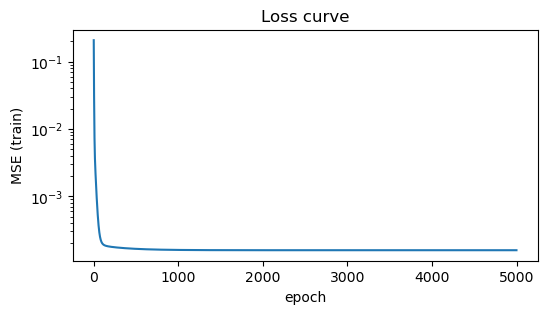

In [23]:
class MyLinearRegression:
    def __init__(self, lr=0.1, epochs=5000):
        self.lr = lr
        self.epochs = epochs

    def fit(self, X, y):
        n, d = X.shape
        self.w = np.zeros(d)
        self.b = 0.0
        self.history = []
        for epoch in range(self.epochs):
            y_hat = X @ self.w + self.b
            err = y_hat - y
            self.history.append(np.mean(err ** 2))
            grad_w = (2 / n) * (X.T @ err)
            grad_b = (2 / n) * err.sum()
            self.w -= self.lr * grad_w
            self.b -= self.lr * grad_b
        return self

    def predict(self, X):
        return X @ self.w + self.b


my_lr = MyLinearRegression().fit(X_train_s, y_train)
p = my_lr.predict(X_test_s)

print("My Linear Regression -> MAE:", round(mae(y_test, p), 4),
      "| RMSE:", round(rmse(y_test, p), 4),
      "| R2:", round(r2(y_test, p), 4))

plt.figure(figsize=(6, 3))
plt.plot(my_lr.history)
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("MSE (train)")
plt.title("Loss curve")
plt.show()

In [24]:
from sklearn.linear_model import LinearRegression

Xb = np.column_stack([X_train_s, np.ones(len(X_train_s))])
theta = np.linalg.solve(Xb.T @ Xb, Xb.T @ y_train)

sk_lr = LinearRegression().fit(X_train_s, y_train)

check = pd.DataFrame({
    "gradient descent (mine)": np.append(my_lr.w, my_lr.b),
    "normal equation (mine)": theta,
    "sklearn": np.append(sk_lr.coef_, sk_lr.intercept_),
}, index=FEATURES + ["bias"])
print(check.round(4))
print()

Xb_test = np.column_stack([X_test_s, np.ones(len(X_test_s))])
print("test RMSE -> gradient descent:", round(rmse(y_test, my_lr.predict(X_test_s)), 5),
      "| normal equation:", round(rmse(y_test, Xb_test @ theta), 5),
      "| sklearn:", round(rmse(y_test, sk_lr.predict(X_test_s)), 5))

           gradient descent (mine)  normal equation (mine)  sklearn
G                           0.2741                  0.2741   0.2741
T2m                        -0.0138                 -0.0138  -0.0138
WS10m                       0.0038                  0.0038   0.0038
sun_elev                   -0.0463                 -0.0463  -0.0463
hour_sin                   -0.0010                 -0.0010  -0.0010
hour_cos                   -0.0399                 -0.0400  -0.0400
doy_sin                     0.0041                  0.0041   0.0041
doy_cos                    -0.0253                 -0.0253  -0.0253
lat                         0.0014                  0.0014   0.0014
lon                        -0.0020                 -0.0020  -0.0020
elevation                  -0.0010                 -0.0010  -0.0010
bias                        0.3695                  0.3695   0.3695

test RMSE -> gradient descent: 0.01307 | normal equation: 0.01307 | sklearn: 0.01307


In [25]:
na = raw.isna().groupby(raw["town"]).sum()
print(na[na.sum(axis=1) > 0])

Empty DataFrame
Columns: [time, P, G(i), H_sun, T2m, WS10m, Int, town, lat, lon, elevation]
Index: []


In [26]:
import time
from sklearn.neighbors import KNeighborsRegressor

class MyKNN:
    def __init__(self, k=10, batch=200):
        self.k = k
        self.batch = batch

    def fit(self, X, y):
        self.X = X
        self.y = y
        self.sq = (X ** 2).sum(axis=1)
        return self

    def predict(self, X):
        out = np.empty(len(X))
        for s in range(0, len(X), self.batch):
            B = X[s:s + self.batch]
            d2 = (B ** 2).sum(axis=1)[:, None] + self.sq[None, :] - 2 * B @ self.X.T
            nearest = np.argpartition(d2, self.k, axis=1)[:, :self.k]
            out[s:s + self.batch] = self.y[nearest].mean(axis=1)
        return out


t0 = time.time()
my_knn = MyKNN(k=10).fit(X_train_s, y_train)
p_knn = my_knn.predict(X_test_s)
print("time:", round(time.time() - t0, 1), "seconds")

print("My KNN -> MAE:", round(mae(y_test, p_knn), 4),
      "| RMSE:", round(rmse(y_test, p_knn), 4),
      "| R2:", round(r2(y_test, p_knn), 4))

sk_knn = KNeighborsRegressor(n_neighbors=10).fit(X_train_s, y_train)
idx = np.random.default_rng(0).choice(len(X_test_s), 1000, replace=False)
print("mean |mine - sklearn| on 1000 test rows:",
      round(np.abs(p_knn[idx] - sk_knn.predict(X_test_s[idx])).mean(), 6))

time: 53.2 seconds
My KNN -> MAE: 0.0161 | RMSE: 0.024 | R2: 0.992
mean |mine - sklearn| on 1000 test rows: 0.0


In [27]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

models = {
    "Decision Tree": DecisionTreeRegressor(max_depth=10, min_samples_leaf=20, random_state=0),
    "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=0),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=0),
}

preds = {
    "Baseline (mean)": baseline,
    "Linear Regression (mine)": my_lr.predict(X_test_s),
    "KNN (mine)": p_knn,
}

for name, m in models.items():
    t0 = time.time()
    m.fit(X_train_s, y_train)
    preds[name] = m.predict(X_test_s)
    print(name, "trained in", round(time.time() - t0, 1), "seconds")

rows = []
for name, p in preds.items():
    p = np.clip(p, 0, None)
    row = {"model": name, "MAE": mae(y_test, p), "RMSE": rmse(y_test, p), "R2": r2(y_test, p)}
    for town in TEST_TOWNS:
        mask = (test["town"] == town).values
        row[f"MAE {town}"] = mae(y_test[mask], p[mask])
    rows.append(row)

results = pd.DataFrame(rows).set_index("model").sort_values("RMSE")
results.round(4)

Decision Tree trained in 1.0 seconds
Random Forest trained in 19.1 seconds
Gradient Boosting trained in 1.2 seconds


,MAE,RMSE,R2,MAE saida,MAE mountlebanon,MAE baalbek
model,,,,,,
Random Forest,0.0012,0.0022,0.9999,0.0011,0.0009,0.0018
Gradient Boosting,0.0018,0.0026,0.9999,0.0017,0.0016,0.0021
Decision Tree,0.0044,0.0065,0.9994,0.0039,0.0038,0.0054
Linear Regression (mine),0.0100,0.0127,0.9977,0.0086,0.0095,0.0120
KNN (mine),0.0161,0.0240,0.9920,0.0162,0.0129,0.0194
Baseline (mean),0.2413,0.2689,-0.0021,0.2343,0.2369,0.2526


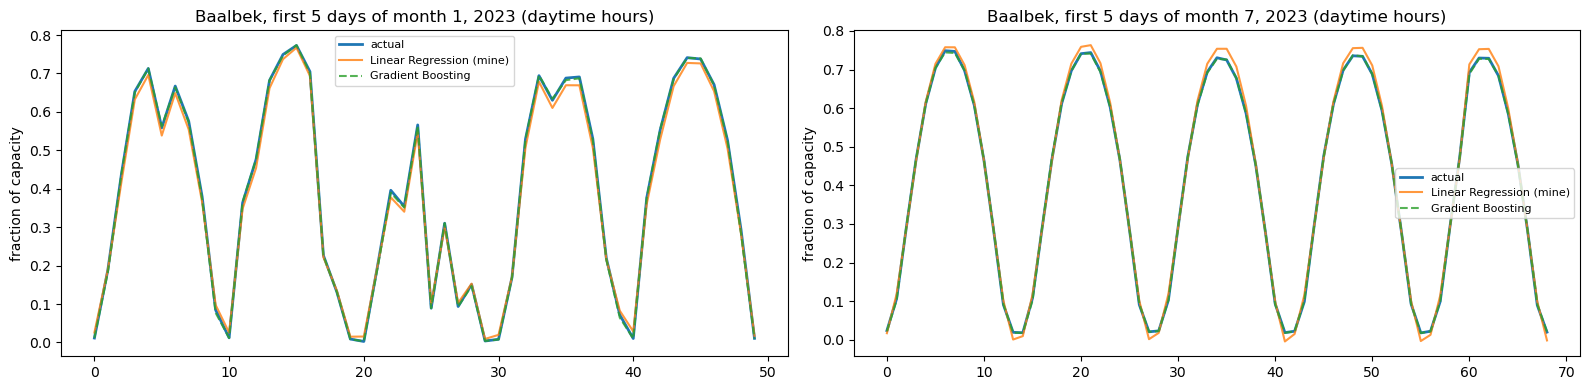

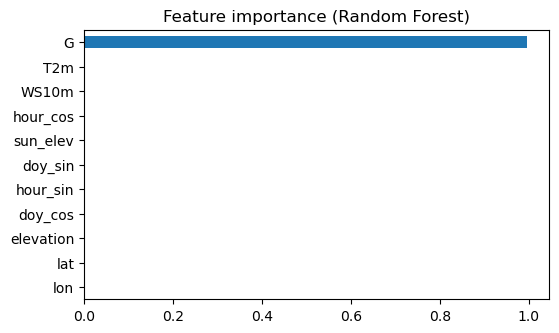

In [28]:
best = models["Gradient Boosting"]
p_best = np.clip(best.predict(X_test_s), 0, None)
p_lr = my_lr.predict(X_test_s)

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
for a, month in zip(ax, [1, 7]):
    w = test[(test["town"] == "baalbek") & (test["time"].dt.year == 2023)
             & (test["time"].dt.month == month) & (test["time"].dt.day <= 5)].index
    a.plot(y_test[w], label="actual", linewidth=2)
    a.plot(p_lr[w], label="Linear Regression (mine)", alpha=0.8)
    a.plot(p_best[w], label="Gradient Boosting", alpha=0.8, linestyle="--")
    a.set_title(f"Baalbek, first 5 days of month {month}, 2023 (daytime hours)")
    a.set_ylabel("fraction of capacity")
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

rf = models["Random Forest"]
pd.Series(rf.feature_importances_, index=FEATURES).sort_values().plot.barh(figsize=(6, 3.5))
plt.title("Feature importance (Random Forest)")
plt.show()

panel tilt: 29.0


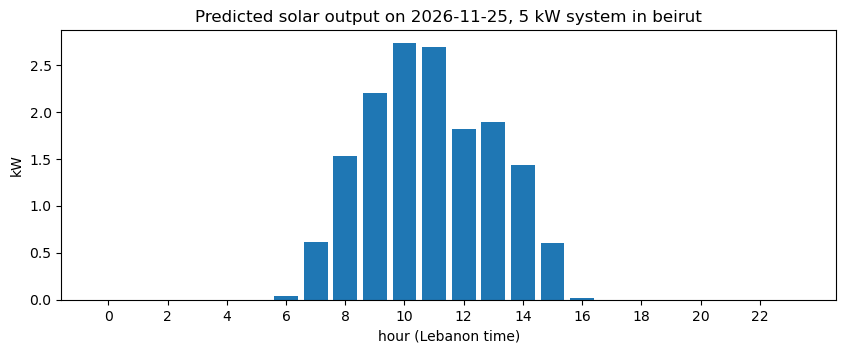

Expected energy tomorrow: 15.6 kWh
Best 3 hours: 9:00 to 12:00
Average day: run heavy appliances one at a time in the best hours.


In [29]:
PLACE = "beirut"
LAT, LON = 33.896, 35.478
SYSTEM_KW = 5

TILT = 31
with open(os.path.join(DATA_DIR, "beirut.csv"), encoding="utf-8", errors="ignore") as f:
    for line in f:
        if line.startswith("Slope"):
            TILT = float(re.findall(r"-?\d+\.?\d*", line)[0])
print("panel tilt:", TILT)

r = requests.get("https://api.open-meteo.com/v1/forecast", timeout=30, params={
    "latitude": LAT, "longitude": LON, "timezone": "GMT", "forecast_days": 3,
    "hourly": "temperature_2m,wind_speed_10m,global_tilted_irradiance",
    "tilt": TILT, "azimuth": 0, "wind_speed_unit": "ms"})
r.raise_for_status()
js = r.json()
h = js["hourly"]

fc = pd.DataFrame({
    "time": pd.to_datetime(h["time"]).tz_localize("UTC") - pd.Timedelta(minutes=30),
    "G": h["global_tilted_irradiance"],
    "T2m": h["temperature_2m"],
    "WS10m": h["wind_speed_10m"],
}).dropna()
fc[["G", "T2m", "WS10m"]] = fc[["G", "T2m", "WS10m"]].astype(float)
fc["lat"], fc["lon"], fc["elevation"] = LAT, LON, js["elevation"]

fc["local"] = fc["time"].dt.tz_convert("Asia/Beirut")
tomorrow = (pd.Timestamp.now(tz="Asia/Beirut") + pd.Timedelta(days=1)).date()
fc = fc[fc["local"].dt.date == tomorrow].reset_index(drop=True)

solar_hour = (fc["time"].dt.hour + fc["time"].dt.minute / 60 + fc["lon"] / 15) % 24
doy = fc["time"].dt.dayofyear
fc["hour_sin"] = np.sin(2 * np.pi * solar_hour / 24)
fc["hour_cos"] = np.cos(2 * np.pi * solar_hour / 24)
fc["doy_sin"] = np.sin(2 * np.pi * doy / 365)
fc["doy_cos"] = np.cos(2 * np.pi * doy / 365)
decl = np.radians(23.44) * np.sin(2 * np.pi * (284 + doy) / 365)
hour_angle = np.radians(15 * (solar_hour - 12))
lat_r = np.radians(fc["lat"])
fc["sun_elev"] = np.degrees(np.arcsin(
    np.sin(lat_r) * np.sin(decl) + np.cos(lat_r) * np.cos(decl) * np.cos(hour_angle)))

X_fc = (fc[FEATURES].values - mu) / sd
fc["kW"] = np.clip(best.predict(X_fc), 0, 1) * SYSTEM_KW
fc.loc[fc["G"] <= 0, "kW"] = 0

total_kwh = fc["kW"].sum()
start = fc["kW"].rolling(3).sum().shift(-2).idxmax()
start_hour = fc["local"].dt.hour[start]
sun_hours = total_kwh / SYSTEM_KW

plt.figure(figsize=(10, 3.5))
plt.bar(fc["local"].dt.hour, fc["kW"])
plt.xlabel("hour (Lebanon time)")
plt.ylabel("kW")
plt.xticks(range(0, 24, 2))
plt.title(f"Predicted solar output on {tomorrow}, {SYSTEM_KW} kW system in {PLACE}")
plt.show()

print(f"Expected energy tomorrow: {total_kwh:.1f} kWh")
print(f"Best 3 hours: {start_hour}:00 to {start_hour + 3}:00")
if sun_hours >= 4.5:
    print("Strong day: run the washing machine and water heater in the best hours.")
elif sun_hours >= 2.5:
    print("Average day: run heavy appliances one at a time in the best hours.")
else:
    print("Weak day: save the battery and postpone heavy loads if you can.")

In [30]:
import joblib

joblib.dump(
    {"model": best, "mu": mu, "sd": sd, "features": FEATURES, "tilt": TILT},
    "solar_model.joblib",
)
print("saved")

saved


In [31]:
towns = raw.groupby("town")[["lat", "lon"]].first()
for t, r in towns.iterrows():
    print(f'    "{t}": ({r.lat}, {r.lon}),')

    "Anjar": (33.739, 35.93),
    "Batroun": (34.255, 35.659),
    "Beirut-RaficHaririAirport.csv": (33.834, 35.496),
    "Bekaa": (33.675, 35.833),
    "Daraya": (33.64, 35.506),
    "Faraya": (34.026, 35.838),
    "Port-Of-Beirut": (33.903, 35.525),
    "Port-Of-Tripoli": (34.451, 35.828),
    "ReneMouawad-Airport.csv": (34.591, 36.011),
    "baalbek": (34.01, 36.212),
    "bcharre": (34.252, 36.042),
    "beirut": (33.896, 35.478),
    "chehime": (33.624, 35.484),
    "debbieh": (33.666, 35.487),
    "halba": (34.544, 36.078),
    "jbeil": (34.127, 35.822),
    "mountlebanon": (33.737, 35.6),
    "nabatieh": (33.284, 35.49),
    "saida": (33.556, 35.395),
    "tripoli": (34.437, 35.835),
    "tyre": (33.272, 35.196),
    "zahle": (33.848, 35.903),
